# Nepal Household Survey — Data Cleaning and Exploratory Data Analysis

## Project Overview

This project focuses on cleaning and exploring a household survey dataset from Nepal.

The notebook is divided into two main stages:

1. **Data Cleaning** — identifying and handling missing values, removing columns with excessive missing data, and preparing a reliable dataset for analysis.
2. **Exploratory Data Analysis (EDA)** — using statistical summaries and visualizations to understand demographic, socioeconomic, and digital-access patterns in the dataset.

The cleaned dataset produced during the data-cleaning stage is used as the foundation for the exploratory analysis.

> **Note:** This project focuses on data cleaning and exploratory data analysis. No machine learning model is implemented in this notebook.

## 1. Import Required Libraries

The following Python libraries are used throughout the project:

- **Pandas** — data loading, cleaning, transformation, and analysis
- **NumPy** — numerical operations
- **Matplotlib** — creating visualizations
- **Seaborn** — statistical visualizations and heatmaps

In [119]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

## 2. Load the Raw Dataset

The original survey dataset is loaded into a Pandas DataFrame named `raw_data`.

The raw dataset is kept unchanged throughout the cleaning process so that it can later be compared with the cleaned dataset.

In [120]:
raw_data=pd.read_csv(r'C:\Users\Dell\OneDrive\Desktop\ALL PROJECTS\DATA-SCIENCE-PROJECTS\PROJECT-3\Data\nepal_survey_messy.csv')

## 3. Initial Dataset Inspection

Before cleaning the data, the dataset is inspected to understand its basic structure.

The following checks are performed:

- Number of rows and columns using `shape`
- Column names and data types using `info()`
- A preview of the first few records using `head()`

This initial inspection helps identify the size, structure, and potential data-quality issues in the raw dataset.

In [121]:
raw_data.shape 

(200, 19)

In [122]:
# CHECK DATA TYPE AND BASIC INFO
raw_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   respondent_id          200 non-null    str    
 1   district               200 non-null    str    
 2   province               200 non-null    str    
 3   age                    160 non-null    float64
 4   gender                 200 non-null    str    
 5   occupation             112 non-null    str    
 6   education_level        104 non-null    str    
 7   monthly_income_nrs     84 non-null     float64
 8   household_size         163 non-null    float64
 9   land_ownership_ropani  87 non-null     float64
 10  electricity_access     200 non-null    str    
 11  drinking_water_source  136 non-null    str    
 12  annual_remittance_nrs  105 non-null    float64
 13  health_insurance       134 non-null    str    
 14  mobile_phone_users     200 non-null    int64  
 15  internet_access  

In [123]:
raw_data.head()


,respondent_id,district,province,age,gender,occupation,education_level,monthly_income_nrs,household_size,land_ownership_ropani,electricity_access,drinking_water_source,annual_remittance_nrs,health_insurance,mobile_phone_users,internet_access,remarks,latitude_gps,survey_notes
0,NP0001,Lalitpur,Bagmati,NaN,Male,Student,NaN,NaN,2.0,10.20,Yes,Jar Water,NaN,NaN,1,No,NaN,NaN,NaN
1,NP0002,Kathmandu,Bagmati,NaN,Female,NaN,NaN,49560.0,3.0,NaN,No,NaN,341069.0,Yes,5,No,NaN,NaN,NaN
2,NP0003,Chitwan,Gandaki,NaN,Male,Doctor,NaN,50893.0,5.0,NaN,No,NaN,104572.0,No,5,Yes,NaN,NaN,NaN
3,NP0004,Pokhara,Bagmati,73.0,Male,Government Job,NaN,25701.0,10.0,14.55,Yes,River,396315.0,Yes,4,No,NaN,27.673545,NaN
4,NP0005,Pokhara,Bagmati,28.0,Other,Doctor,NaN,NaN,NaN,16.38,No,River,NaN,No,1,No,NaN,NaN,Elderly alone


## 4. Missing Value Analysis

Missing values can affect statistical analysis and may cause problems in later stages of a data project.

In this section, the number and percentage of missing values are calculated for each column. A summary table is created and sorted so that columns with the highest proportion of missing data can be identified easily.

A heatmap is also used to visually inspect the distribution of missing values across the dataset.

In [124]:
# count how many missing values are in each column
missing_count=raw_data.isnull().sum()

# calculate the percentage of missing values
missing_percent=(missing_count/len(raw_data))*100

# combine both into one table
missing_summary = pd.DataFrame({
    'missing count': missing_count,
    'missing percent(%)': missing_percent.round(2)
})
# sort missing percentage
missing_summary= missing_summary.sort_values('missing percent(%)',ascending=False)

# sort only columns that has at least 1 missing values
missing_summary[missing_summary['missing count']>0]

,missing count,missing percent(%)
remarks,190,95.0
survey_notes,175,87.5
latitude_gps,174,87.0
monthly_income_nrs,116,58.0
land_ownership_ropani,113,56.5
education_level,96,48.0
annual_remittance_nrs,95,47.5
occupation,88,44.0
health_insurance,66,33.0
drinking_water_source,64,32.0


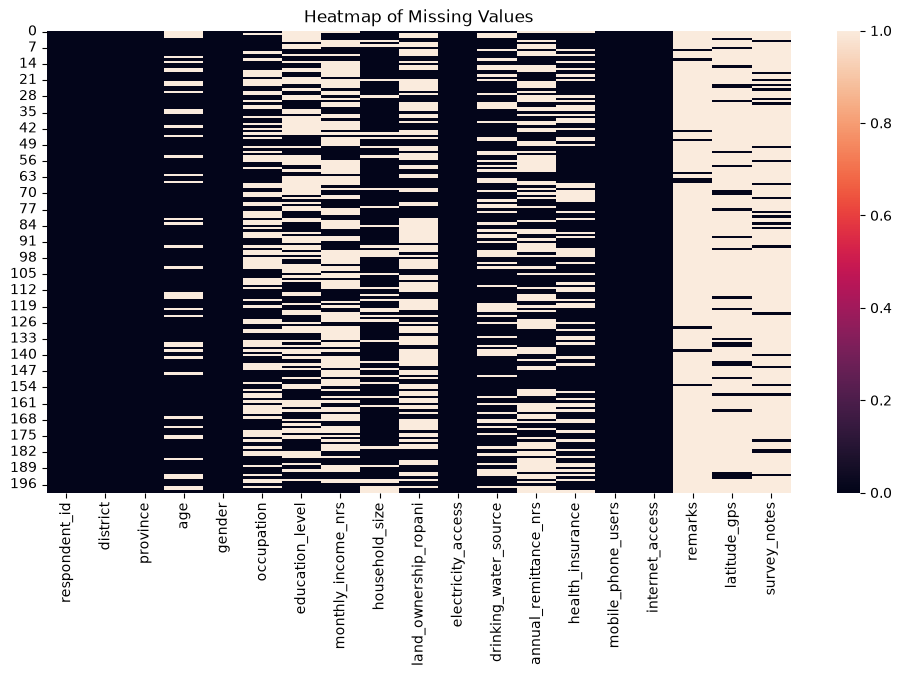

In [125]:
# HEATMAP OF MISSING VALUES
plt.figure(figsize=(12,6))
sns.heatmap(raw_data.isnull())
plt.title('Heatmap of Missing Values')
plt.show()

## 5. Create a Working Copy

A copy of the original dataset is created and stored in `df_clean`.

The original `raw_data` DataFrame is preserved so that the cleaned dataset can be compared with the original dataset later.

All cleaning operations from this point onward are performed on `df_clean`.

In [126]:
# MAKE A COPY OF THE ORIGIONAL DATA
# WE WILL CLEAN DF_CLEAN AND KEEP raw_data UNTOUCHED

df_clean=raw_data.copy()

print('origional dataframe shape:',raw_data.shape)
print('copy dataframe shape',raw_data.shape)
print()
print('These should be equal. We are working on df_clean now.')

origional dataframe shape: (200, 19)
copy dataframe shape (200, 19)

These should be equal. We are working on df_clean now.


## 6. Remove Columns with Excessive Missing Values

Columns containing a very high percentage of missing values may provide limited analytical value and can be difficult to recover reliably.

In this dataset, columns with more than 80% missing values have been identified and removed from the working dataset.

This reduces unnecessary missing-data problems while retaining columns that contain sufficient information for analysis.

In [127]:
# Display the updated dataset
# Remove unnecessary columns from the dataset
df_clean = raw_data.drop(columns=['remarks', 'latitude_gps', 'survey_notes'], errors='ignore').copy()

# Display the updated dataset
df_clean.head()

,respondent_id,district,province,age,gender,occupation,education_level,monthly_income_nrs,household_size,land_ownership_ropani,electricity_access,drinking_water_source,annual_remittance_nrs,health_insurance,mobile_phone_users,internet_access
0,NP0001,Lalitpur,Bagmati,NaN,Male,Student,NaN,NaN,2.0,10.20,Yes,Jar Water,NaN,NaN,1,No
1,NP0002,Kathmandu,Bagmati,NaN,Female,NaN,NaN,49560.0,3.0,NaN,No,NaN,341069.0,Yes,5,No
2,NP0003,Chitwan,Gandaki,NaN,Male,Doctor,NaN,50893.0,5.0,NaN,No,NaN,104572.0,No,5,Yes
3,NP0004,Pokhara,Bagmati,73.0,Male,Government Job,NaN,25701.0,10.0,14.55,Yes,River,396315.0,Yes,4,No
4,NP0005,Pokhara,Bagmati,28.0,Other,Doctor,NaN,NaN,NaN,16.38,No,River,NaN,No,1,No


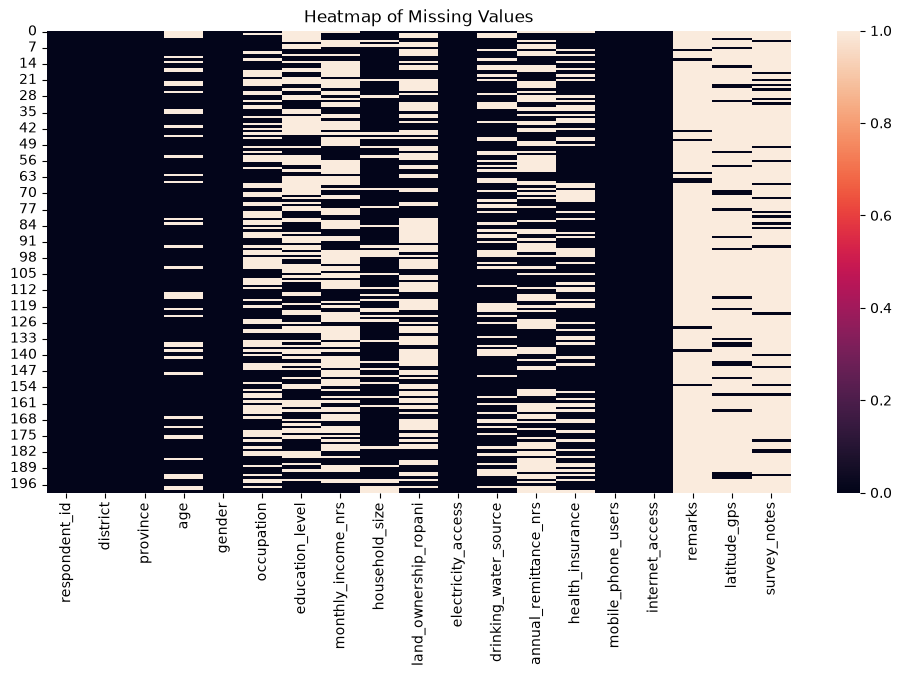

In [128]:
# HEATMAP OF MISSING VALUES
plt.figure(figsize=(12,6))
sns.heatmap(raw_data.isnull())
plt.title('Heatmap of Missing Values')
plt.show()

## 7. Handle Remaining Missing Values

After removing columns with excessive missing values, the remaining missing values are handled according to the type and characteristics of each variable.

Different imputation methods are used:

- **Mean** — used for numerical variables where the average is considered appropriate.
- **Median** — used for numerical variables where the median provides a more robust measure against extreme values.
- **Mode** — used for categorical variables by replacing missing values with the most frequent category.
- **Backward Fill (`bfill`)** — fills a missing value using the next available value.
- **Forward Fill (`ffill`)** — fills a missing value using the previous available value.

The appropriate method is selected based on the variable being cleaned.

### 7.1 Mean Imputation — Household Size

The `household_size` variable is numerical. Missing values are replaced with the mean household size.

The number of missing values is checked before and after imputation to verify that the operation was successful.

In [129]:
# USE MEAN FOR NUMERIC COLUMN WITH NORMAL DISTRIBUTION.
# CHECK MISSING COUNT BEFORE FILLING
print("Missing in household_size before:", df_clean["household_size"].isnull().sum())

# Calculate the mean (average)
mean_values = df_clean["household_size"].mean()
print("Mean value of household_size:", round(mean_values, 2))

# fill the missing values with the mean_values
df_clean["household_size"] = df_clean["household_size"].fillna(mean_values)
print("Missing in household_size after :", df_clean["household_size"].isnull().sum())

Missing in household_size before: 37
Mean value of household_size: 5.64
Missing in household_size after : 0


### 7.2 Compare Mean and Median for Numerical Variables

Before choosing an imputation method for several numerical variables, their mean and median values are compared.

The variables examined are:

- Land ownership
- Monthly income
- Annual remittance

Comparing the mean and median helps determine whether the data may contain large or unusual values that could influence the mean.

In [130]:
avg = df_clean["land_ownership_ropani"].mean()
midd = df_clean["land_ownership_ropani"].median()

print(avg, midd)

9.637011494252874 9.23


In [131]:
avg=df_clean["monthly_income_nrs"].mean()
midd=df_clean["monthly_income_nrs"].median()

print(avg, midd)

74624.42857142857 72828.0


In [132]:
avg=df_clean["annual_remittance_nrs"].mean()
midd=df_clean["annual_remittance_nrs"].median()

print(avg, midd)

259076.9619047619 250705.0


### 7.3 Median Imputation for Numerical Variables

The median is used to fill missing values in selected numerical variables.
The median is less affected by extreme values than the mean, making it useful for variables such as income, land ownership, remittance, and age.
The following variables are handled using median imputation:

- Monthly income
- Land ownership
- Annual remittance
- Age

In [133]:
# FILL MONTHLY_INCOME(NRS) WITH MEDIAN
print("Missing in monthly_income_nrs before:", df_clean["monthly_income_nrs"].isnull().sum())

median_income = df_clean["monthly_income_nrs"].median()
print("Median monthly income is:", median_income)

df_clean["monthly_income_nrs"] = df_clean["monthly_income_nrs"].fillna(median_income)

print("Missing in monthly_income_nrs after:", df_clean["monthly_income_nrs"].isnull().sum())

Missing in monthly_income_nrs before: 116
Median monthly income is: 72828.0
Missing in monthly_income_nrs after: 0


In [134]:
# FILL LAND OWNERSHIP ROPANI WITH MEDIAN
print("Missing in land_ownership_ropani before:", df_clean["land_ownership_ropani"].isnull().sum())

median_land = df_clean["land_ownership_ropani"].median()

df_clean["land_ownership_ropani"] = df_clean["land_ownership_ropani"].fillna(median_land)

print("Missing in land_ownership_ropani after:", df_clean["land_ownership_ropani"].isnull().sum())

Missing in land_ownership_ropani before: 113
Missing in land_ownership_ropani after: 0


In [135]:
# FILL ANNUAL REMITTANCE WITH MEDIAN
print("Missing in annual_remittance_nrs before:", df_clean["annual_remittance_nrs"].isnull().sum())

median_remittance = df_clean["annual_remittance_nrs"].median()

df_clean["annual_remittance_nrs"] = df_clean["annual_remittance_nrs"].fillna(median_remittance)

print("Missing in annual_remittance_nrs after:", df_clean["annual_remittance_nrs"].isnull().sum())

Missing in annual_remittance_nrs before: 95
Missing in annual_remittance_nrs after: 0


In [136]:
# FILL AGE WITH MEDIAN
# AGE CAN SOMETIMES HAVE EXTREME VALUE SO MEDIUM IS BETTER
print("Missing in age before:", df_clean["age"].isnull().sum())


median_age = df_clean["age"].median()

df_clean["age"] = df_clean["age"].fillna(median_age)

print("Missing in age after:", df_clean["age"].isnull().sum())

Missing in age before: 40
Missing in age after: 0


### 7.4 Inspect the Cleaned Data

A preview of the cleaned DataFrame is displayed to confirm that the recent transformations have been applied correctly.

In [137]:
df_clean.head()

,respondent_id,district,province,age,gender,occupation,education_level,monthly_income_nrs,household_size,land_ownership_ropani,electricity_access,drinking_water_source,annual_remittance_nrs,health_insurance,mobile_phone_users,internet_access
0,NP0001,Lalitpur,Bagmati,49.0,Male,Student,NaN,72828.0,2.000000,10.20,Yes,Jar Water,250705.0,NaN,1,No
1,NP0002,Kathmandu,Bagmati,49.0,Female,NaN,NaN,49560.0,3.000000,9.23,No,NaN,341069.0,Yes,5,No
2,NP0003,Chitwan,Gandaki,49.0,Male,Doctor,NaN,50893.0,5.000000,9.23,No,NaN,104572.0,No,5,Yes
3,NP0004,Pokhara,Bagmati,73.0,Male,Government Job,NaN,25701.0,10.000000,14.55,Yes,River,396315.0,Yes,4,No
4,NP0005,Pokhara,Bagmati,28.0,Other,Doctor,NaN,72828.0,5.638037,16.38,No,River,250705.0,No,1,No


### 7.5 Inspect Categorical Variables

The frequency of each category is examined before filling missing categorical values.
This helps identify the most common category that can be used for mode-based imputation.

In [138]:
df_clean["education_level"].value_counts()

education_level
SLC                    20
Bachelors              19
Masters                15
No Formal Education    15
Secondary              14
Primary                12
Intermediate            9
Name: count, dtype: int64

### 7.6 Mode Imputation for Categorical Variables

For categorical variables, missing values are replaced with the most frequently occurring category, known as the **mode**.
In this section, mode imputation is applied to:

- Education level
- Occupation

The missing-value count is checked before and after each replacement.

In [139]:
# FILL EDUCATION LEVEL WITH MODE
print("Missing in education_level before:", df_clean["education_level"].isnull().sum())

# MODE() RETURNS A SERIES, WE TAKE THE FIRST VALUE
mode_education = df_clean["education_level"].mode()[0]
print("Most common education level:", mode_education)

df_clean["education_level"] = df_clean["education_level"].fillna(mode_education)

print("Missing in education_level after :", df_clean["education_level"].isnull().sum())

Missing in education_level before: 96
Most common education level: SLC
Missing in education_level after : 0


#### Inspect Occupation Categories
The frequency of occupation categories is examined to identify the most common occupation before applying mode imputation.

In [140]:
df_clean["occupation"].value_counts()

occupation
Daily Wage        23
Business          18
Engineer          16
Doctor            13
Student           12
Teacher           12
Government Job    11
Farmer             7
Name: count, dtype: int64

In [141]:
# FILL OCCUPATION WITH MODE
print("Missing in occupation before :", df_clean["occupation"].isnull().sum())

mode_occupation = df_clean["occupation"].mode()[0]
print("Most Common occupation:", mode_occupation)

df_clean["occupation"] = df_clean["occupation"].fillna(mode_occupation)

print("Missing in occupation after :", df_clean["occupation"].isnull().sum())

Missing in occupation before : 88
Most Common occupation: Daily Wage
Missing in occupation after : 0


### 7.7 Backward Fill for Health Insurance

The `health_insurance` variable is categorical.
Backward fill (`bfill`) is used to replace missing values with the next available value in the column.
The number of missing values is checked before and after the operation to verify the result.

In [142]:
# FILL HEALTH INSURANCE USING BACKWARD FILL
print('missing in  health insurance before',df_clean['health_insurance'].isnull().sum())

df_clean['health_insurance']=df_clean['health_insurance'].bfill()

print('missing in health insurance after:',df_clean['health_insurance'].isnull().sum())

missing in  health insurance before 66
missing in health insurance after: 1


### 7.8 Forward Fill for Drinking Water Source

The `drinking_water_source` variable is categorical.

Forward fill (`ffill`) is used to replace missing values using the previous available value in the column.

The distribution of categories is inspected before the missing values are filled.

   

In [143]:
df_clean['drinking_water_source'].value_counts()

drinking_water_source
River        41
Jar Water    40
Well         31
Tap          24
Name: count, dtype: int64

In [144]:
# FILL drinking_water_source USING FORWARD FILL
print('missing in  drinking_water_source before',df_clean['drinking_water_source'].isnull().sum())

df_clean['drinking_water_source']=df_clean['drinking_water_source'].ffill()

print('missing in drinking_water_source after:',df_clean['drinking_water_source'].isnull().sum())

missing in  drinking_water_source before 64
missing in drinking_water_source after: 0


## 8. Validate the Cleaned Dataset

After all missing-value treatments have been applied, the dataset is checked again to determine whether any missing values remain.

A total missing-value count is calculated across the entire DataFrame.

The goal of this stage is to confirm that the cleaning process has handled the missing values successfully.

In [145]:
# check if are any missing values left
total_missing=df_clean.isnull().sum().sum()
print('total missing values remaining in df_clean:',total_missing)

if total_missing==0:
    print('all missing values have been handled')
else:
    print('some missing values still remain.Check the columns below')
    print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

total missing values remaining in df_clean: 1
some missing values still remain.Check the columns below
health_insurance    1
dtype: int64


## 9. Compare the Original and Cleaned Datasets

The original and cleaned datasets are compared using:

- Number of rows and columns
- Total number of missing values

This comparison helps confirm that the cleaning process removed the intended columns and handled the missing values without unexpectedly changing the number of records.

In [146]:
# Compare original and cleaned dataframe
print("Original data shape :", raw_data.shape)
print("Cleaned data shape  :", df_clean.shape)
print()
print("Original missing values total :", raw_data.isnull().sum().sum())
print("Cleaned missing values total  :", df_clean.isnull().sum().sum())

Original data shape : (200, 19)
Cleaned data shape  : (200, 16)

Original missing values total : 1254
Cleaned missing values total  : 1


## 10. Visual Comparison of Missing Values

Heatmaps are used to compare the distribution of missing values before and after cleaning.

The first heatmap represents the original dataset, while the second represents the cleaned dataset.

A successful cleaning process should show a substantial reduction or elimination of missing-value patterns.

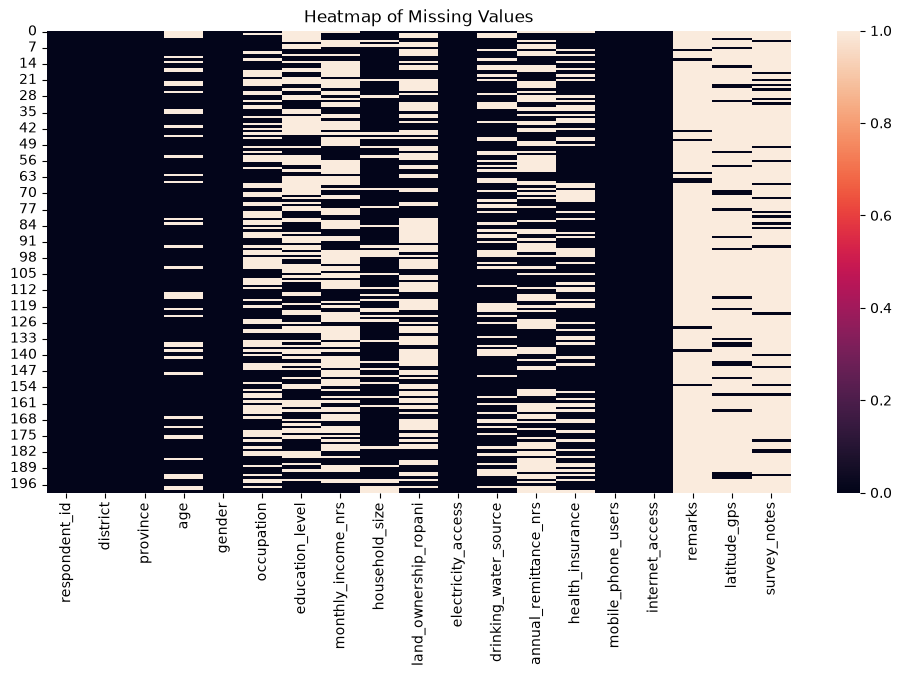

In [147]:
# HEATMAP OF MISSING VALUES
plt.figure(figsize=(12,6))
sns.heatmap(raw_data.isnull())
plt.title('Heatmap of Missing Values')
plt.show()

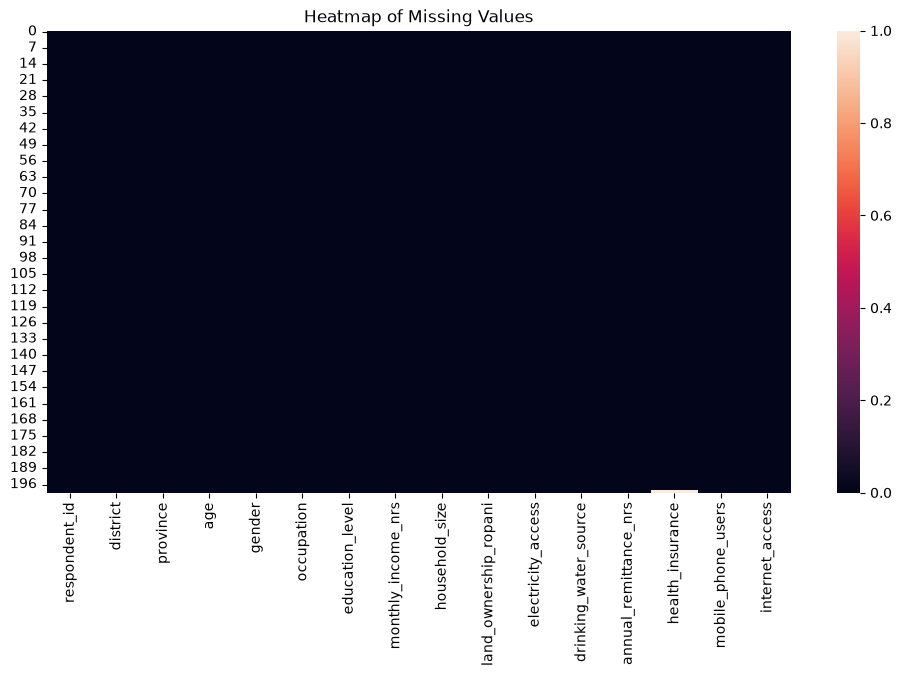

In [148]:
# HEATMAP OF MISSING VALUES
plt.figure(figsize=(12,6))
sns.heatmap(df_clean.isnull())
plt.title('Heatmap of Missing Values')
plt.show()

## 11. Final Inspection of the Cleaned Dataset

The cleaned DataFrame is inspected one final time to verify:

- Data types
- Number of records
- Number of columns
- Overall structure of the cleaned dataset

The original dataset is also inspected for comparison.

In [149]:
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   respondent_id          200 non-null    str    
 1   district               200 non-null    str    
 2   province               200 non-null    str    
 3   age                    200 non-null    float64
 4   gender                 200 non-null    str    
 5   occupation             200 non-null    str    
 6   education_level        200 non-null    str    
 7   monthly_income_nrs     200 non-null    float64
 8   household_size         200 non-null    float64
 9   land_ownership_ropani  200 non-null    float64
 10  electricity_access     200 non-null    str    
 11  drinking_water_source  200 non-null    str    
 12  annual_remittance_nrs  200 non-null    float64
 13  health_insurance       199 non-null    str    
 14  mobile_phone_users     200 non-null    int64  
 15  internet_access  

In [150]:
raw_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   respondent_id          200 non-null    str    
 1   district               200 non-null    str    
 2   province               200 non-null    str    
 3   age                    160 non-null    float64
 4   gender                 200 non-null    str    
 5   occupation             112 non-null    str    
 6   education_level        104 non-null    str    
 7   monthly_income_nrs     84 non-null     float64
 8   household_size         163 non-null    float64
 9   land_ownership_ropani  87 non-null     float64
 10  electricity_access     200 non-null    str    
 11  drinking_water_source  136 non-null    str    
 12  annual_remittance_nrs  105 non-null    float64
 13  health_insurance       134 non-null    str    
 14  mobile_phone_users     200 non-null    int64  
 15  internet_access  

In [151]:
df_clean.head()

,respondent_id,district,province,age,gender,occupation,education_level,monthly_income_nrs,household_size,land_ownership_ropani,electricity_access,drinking_water_source,annual_remittance_nrs,health_insurance,mobile_phone_users,internet_access
0,NP0001,Lalitpur,Bagmati,49.0,Male,Student,SLC,72828.0,2.000000,10.20,Yes,Jar Water,250705.0,Yes,1,No
1,NP0002,Kathmandu,Bagmati,49.0,Female,Daily Wage,SLC,49560.0,3.000000,9.23,No,Jar Water,341069.0,Yes,5,No
2,NP0003,Chitwan,Gandaki,49.0,Male,Doctor,SLC,50893.0,5.000000,9.23,No,Jar Water,104572.0,No,5,Yes
3,NP0004,Pokhara,Bagmati,73.0,Male,Government Job,SLC,25701.0,10.000000,14.55,Yes,River,396315.0,Yes,4,No
4,NP0005,Pokhara,Bagmati,28.0,Other,Doctor,SLC,72828.0,5.638037,16.38,No,River,250705.0,No,1,No


In [152]:
print(df_clean.shape)

(200, 16)


## 12. Save the Cleaned Dataset

The cleaned DataFrame is exported to a new CSV file named:

`nepal_survey_cleaned.csv`

The original dataset is preserved separately, while the newly created CSV contains the cleaned version that will be used for exploratory data analysis.

In [153]:
#SAVE THE CLEANED DATA TO CSV
# Save the cleaned dataframe to a new CSV file
df_clean.to_csv("nepal_survey_cleaned.csv", index=False)

print("Cleaned data saved as: nepal_survey_cleaned.csv")
print("Shape of saved file  :", df_clean.shape)

Cleaned data saved as: nepal_survey_cleaned.csv
Shape of saved file  : (200, 16)


## 13. Data Cleaning Summary

The data-cleaning stage has completed the following tasks:

1. Loaded the original Nepal household survey dataset.
2. Inspected the dataset structure and data types.
3. Identified missing values and calculated their percentages.
4. Created a separate working copy of the original dataset.
5. Removed selected columns containing excessive missing values.
6. Applied appropriate missing-value treatments to the remaining variables.
7. Verified the cleaned dataset for remaining missing values.
8. Compared the original and cleaned datasets.
9. Exported the cleaned dataset as `nepal_survey_cleaned.csv`.

The resulting cleaned dataset is now ready for exploratory data analysis.

# Exploratory Data Analysis (EDA)

## 14. Introduction to Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed on the cleaned dataset to understand its main characteristics and identify patterns, distributions, and relationships within the data.

The analysis uses:

- Descriptive statistics
- Frequency analysis
- Bar charts
- Pie charts
- Histograms
- Line plots
- Box plots
- Scatter plots
- Heatmaps

The objective is to understand demographic, household, socioeconomic, and digital-access characteristics represented in the survey data.

## 15. Load the Cleaned Dataset

The cleaned CSV file created during the data-cleaning stage is loaded into a new DataFrame named `df`.

This cleaned dataset is used for all subsequent exploratory analysis and visualizations.

In [154]:
df=pd.read_csv("nepal_survey_cleaned.csv")

## 16. Inspect the Cleaned Dataset

The cleaned dataset is inspected again using `info()` and `head()` to confirm its structure before beginning the analysis.

This provides a final overview of the available variables and records.

In [155]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   respondent_id          200 non-null    str    
 1   district               200 non-null    str    
 2   province               200 non-null    str    
 3   age                    200 non-null    float64
 4   gender                 200 non-null    str    
 5   occupation             200 non-null    str    
 6   education_level        200 non-null    str    
 7   monthly_income_nrs     200 non-null    float64
 8   household_size         200 non-null    float64
 9   land_ownership_ropani  200 non-null    float64
 10  electricity_access     200 non-null    str    
 11  drinking_water_source  200 non-null    str    
 12  annual_remittance_nrs  200 non-null    float64
 13  health_insurance       199 non-null    str    
 14  mobile_phone_users     200 non-null    int64  
 15  internet_access  

In [156]:
df.head()

,respondent_id,district,province,age,gender,occupation,education_level,monthly_income_nrs,household_size,land_ownership_ropani,electricity_access,drinking_water_source,annual_remittance_nrs,health_insurance,mobile_phone_users,internet_access
0,NP0001,Lalitpur,Bagmati,49.0,Male,Student,SLC,72828.0,2.000000,10.20,Yes,Jar Water,250705.0,Yes,1,No
1,NP0002,Kathmandu,Bagmati,49.0,Female,Daily Wage,SLC,49560.0,3.000000,9.23,No,Jar Water,341069.0,Yes,5,No
2,NP0003,Chitwan,Gandaki,49.0,Male,Doctor,SLC,50893.0,5.000000,9.23,No,Jar Water,104572.0,No,5,Yes
3,NP0004,Pokhara,Bagmati,73.0,Male,Government Job,SLC,25701.0,10.000000,14.55,Yes,River,396315.0,Yes,4,No
4,NP0005,Pokhara,Bagmati,28.0,Other,Doctor,SLC,72828.0,5.638037,16.38,No,River,250705.0,No,1,No


## 17. Categorical Frequency Analysis

The frequency of respondents by district is calculated using `value_counts()`.

This provides an initial understanding of how the survey records are distributed geographically.

In [157]:
df['district'].value_counts()

district
Pokhara       27
Lalitpur      26
Nepalgunj     25
Chitwan       20
Bhaktapur     18
Hetauda       18
Butwal        18
Kathmandu     17
Dharan        17
Biratnagar    14
Name: count, dtype: int64

### 17.1 Respondent Distribution by Province

A pie chart is used to visualize the proportion of respondents belonging to each province.

This helps show the relative representation of provinces within the survey dataset.

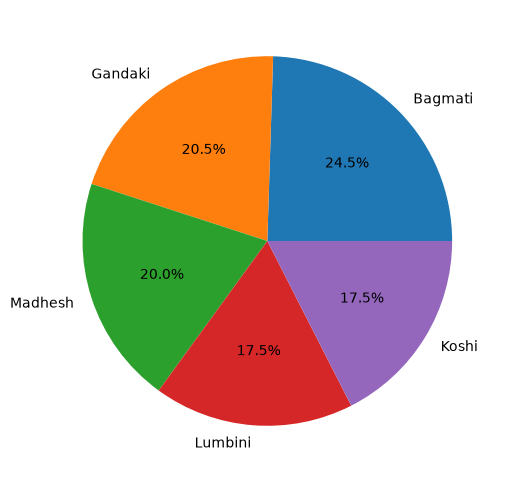

In [158]:
# PIE CHART DISTRIBUTION OF PROVINCE
pro_counts=df_clean['province'].value_counts()
plt.figure(figsize=(12, 6))
plt.pie(pro_counts, labels=pro_counts.index, autopct='%1.1f%%')
plt.show()

### 17.2 Respondent Distribution by District

A pie chart is used to examine how respondents are distributed across districts.

This provides a visual representation of the geographic composition of the survey.

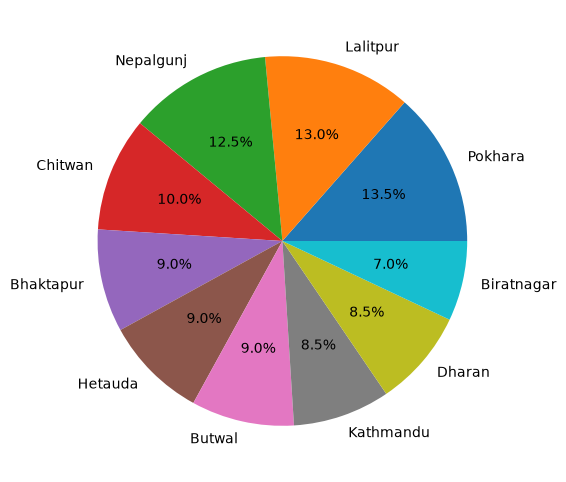

In [159]:
# PIE CHART DISTRIBUTION OF DISTRICT
dist_counts = df_clean["district"].value_counts()

plt.figure(figsize=(12, 6))
plt.pie(dist_counts, labels=dist_counts.index, autopct='%1.1f%%')
plt.show()

### 17.3 Respondent Count by District

Bar charts are used to compare the number of respondents across districts.

Unlike a pie chart, a bar chart makes it easier to compare the sizes of individual districts directly.

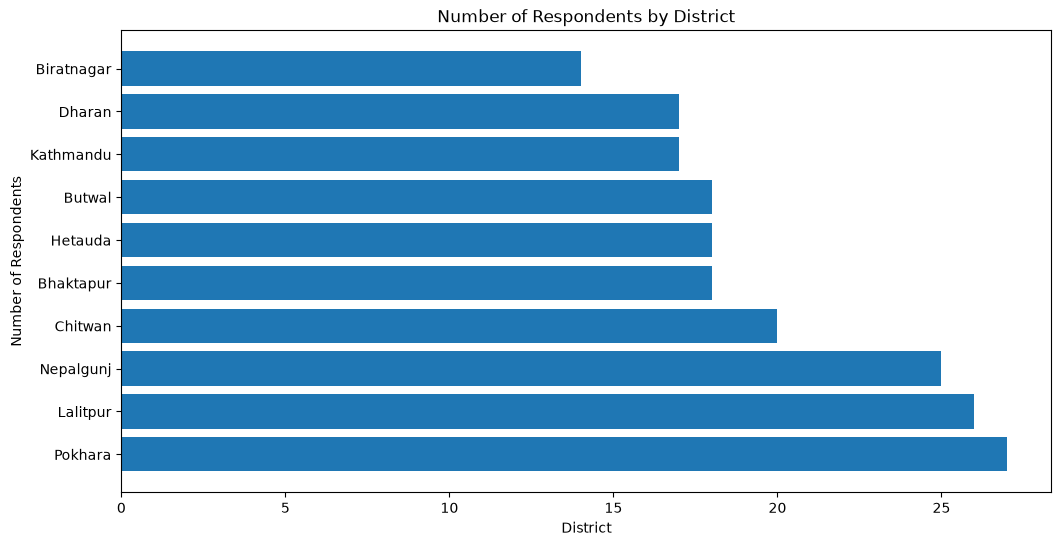

In [160]:
# HORIZONTAL BAR GRAPH OF DISTRICT COUNTS 
plt.figure(figsize=(12, 6))
plt.barh(dist_counts.index, dist_counts.values)
plt.title("Number of Respondents by District")
plt.xlabel("District")
plt.ylabel("Number of Respondents")
plt.show()

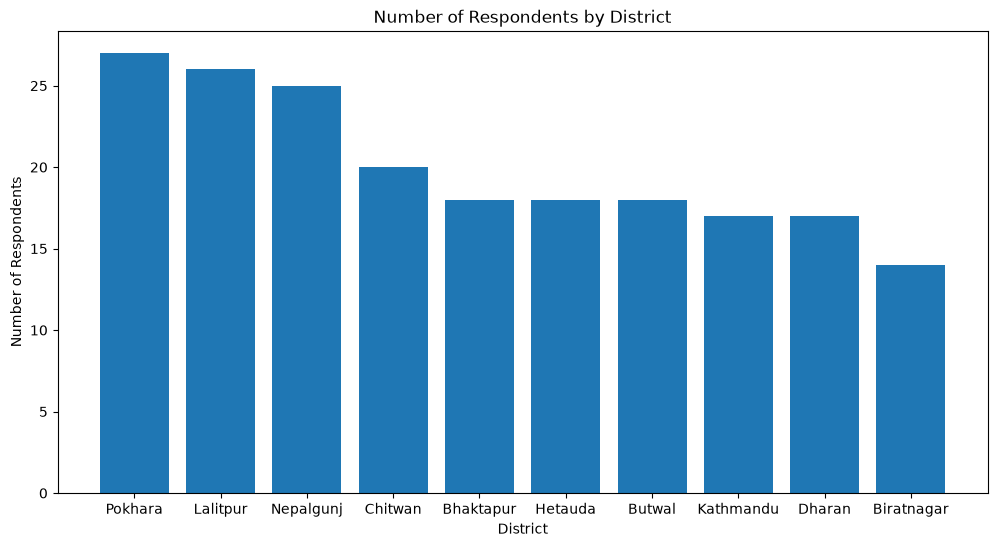

In [161]:
#  HORIZONTAL BAR GRAPH OF DISTRICT COUNTS 
plt.figure(figsize=(12, 6))
plt.bar(dist_counts.index, dist_counts.values)
plt.title("Number of Respondents by District")
plt.xlabel("District")
plt.ylabel("Number of Respondents")
plt.show()

## 18. Digital Access Analysis

The next visualizations explore digital-access characteristics within the survey data.

The number of mobile phone users is examined across provinces to identify differences in mobile-phone usage between geographic regions.

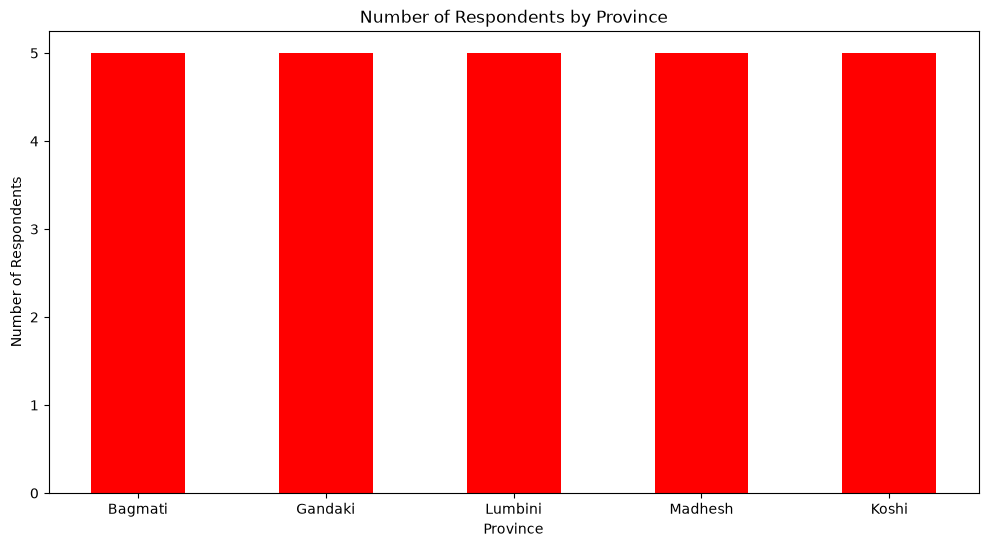

In [162]:
# BAR GRAPH OF PROVINCE VS PHONE USERS
plt.figure(figsize=(12, 6))
plt.bar(df_clean['province'], df_clean['mobile_phone_users'],color='red',width=0.5)
plt.title("Number of Respondents by Province")
plt.xlabel("Province")
plt.ylabel("Number of Respondents")
plt.show()

## 19. Income Comparison by Province

Monthly income is examined across provinces to explore differences in the recorded income levels between geographic regions.

The visualization provides a basic comparison of the income values represented in the dataset.

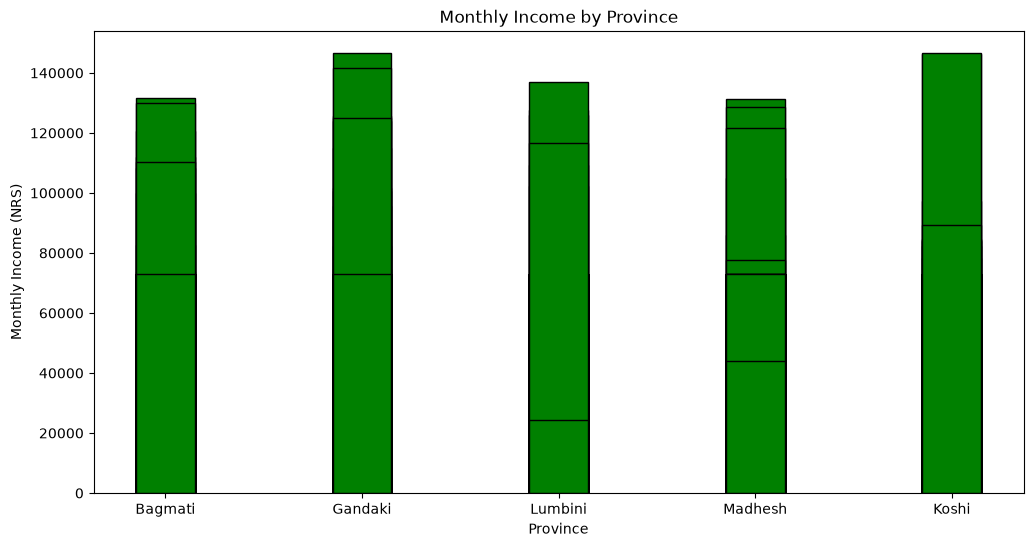

In [163]:
# BAR GRAPH OF PROVINCE VS MONTHLY INCOME(NRS)
plt.figure(figsize=(12, 6))
plt.bar(df_clean['province'], df_clean['monthly_income_nrs'],color='green',width=0.3,edgecolor='black')
plt.title("Monthly Income by Province")
plt.xlabel("Province")
plt.ylabel("Monthly Income (NRS)")
plt.show()

## 20. Demographic Analysis

Age and gender are explored to examine the demographic characteristics represented in the survey dataset.

A graphical comparison is used to visualize the relationship between the recorded age and gender variables.

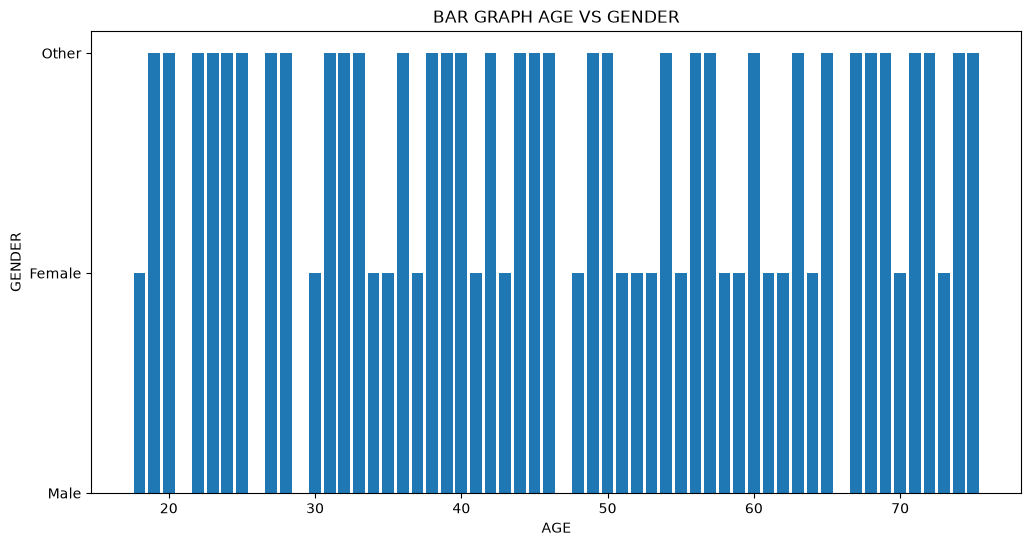

In [164]:
# BAR GRAPH AGE VS GENDER
plt.figure(figsize=(12, 6))
plt.bar(df['age'], df['gender'])
plt.title("BAR GRAPH AGE VS GENDER")
plt.xlabel("AGE")
plt.ylabel("GENDER")
plt.show()

## 21. Average Household Size by Province

The dataset is grouped by province and the average household size is calculated for each province.

A line plot is then used to compare the average household size across provinces.

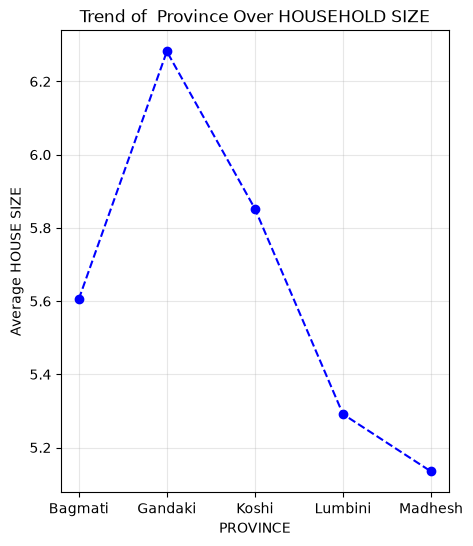

In [165]:
# PLOT-7: GROUP THE DATA BY PROVINCE AND CALCULATE THE AVERAGE HOUSEHOLD SIZE FOR EACH PROVINCE

avg_housesize=df_clean.groupby('province')['household_size'].mean()
plt.figure(figsize=(5,6))
plt.plot(avg_housesize.index, avg_housesize.values, marker='o', linestyle='--', color='blue')
plt.xlabel('PROVINCE')
plt.ylabel('Average HOUSE SIZE')
plt.title('Trend of  Province Over HOUSEHOLD SIZE')
plt.grid(True,alpha=0.3)
plt.show()

## 22. Age and Gender Distribution

A scatter plot is used to visualize the recorded age and gender values.

This provides another graphical view of the distribution of these two demographic variables.

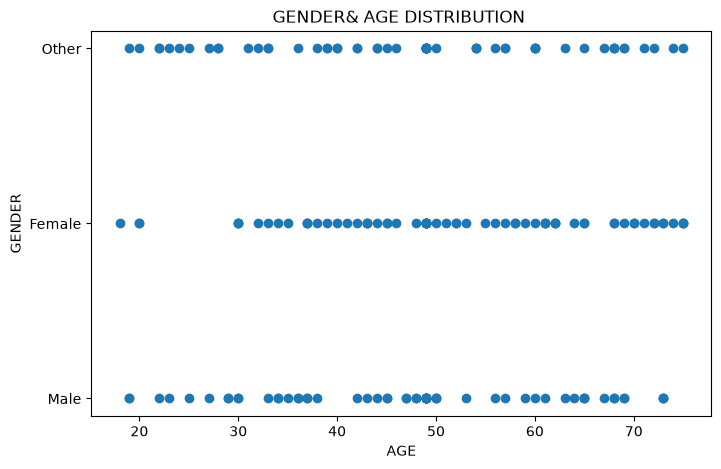

In [166]:
#  SCATTER PLOT 
plt.figure(figsize=(8,5))
plt.scatter(df_clean['age'],df_clean['gender'])
plt.title('GENDER& AGE DISTRIBUTION ')
plt.xlabel('AGE')
plt.ylabel('GENDER')
plt.show()

## 23. Mobile Phone Users by Age Group

The respondents are divided into predefined age groups, and the distribution of mobile phone users is examined within each group.

A box plot is used to compare the distribution, central tendency, spread, and potential outliers across age groups.

<Figure size 1000x600 with 0 Axes>

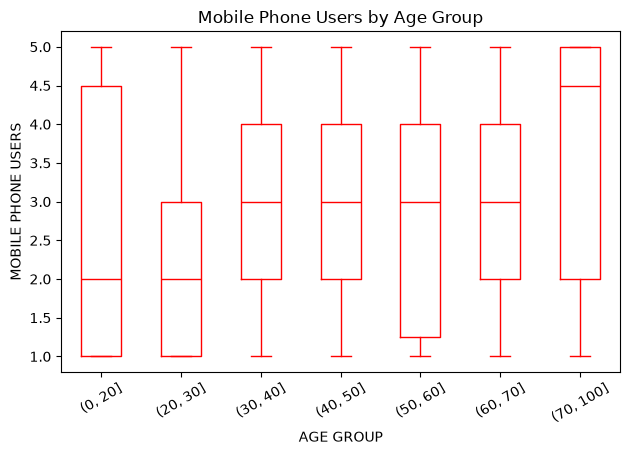

In [167]:
#PLOT-10: BOXPLOT OF LAND MOBILE PHONE USERS BY AGE GROUP

age_bins = [0, 20, 30, 40, 50, 60, 70, 100]
df_clean['Age_Group'] = pd.cut(df_clean['age'], bins=age_bins)
plt.figure(figsize=(10, 6))
df_clean.boxplot(
    column='mobile_phone_users',
    by='Age_Group',
    grid=False,
    color='red'
)

plt.title('Mobile Phone Users by Age Group')
plt.suptitle('')
plt.xlabel('AGE GROUP')
plt.ylabel('MOBILE PHONE USERS')

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 24. Distribution Analysis

Histograms are generally used to visualize the distribution of numerical variables.

The following section explores the distribution of selected variables within the survey dataset.

Text(0.5, 0, 'PROVINCE')

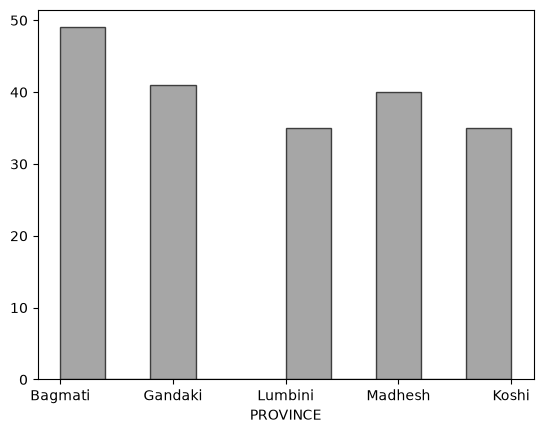

In [168]:
#  HISTOGRAM FOR PROVINCE
plt.hist(df_clean['province'], color='gray', alpha=0.7,edgecolor='black')
plt.xlabel('PROVINCE')

### 25. Monthly Income Distribution

A histogram is used to examine the distribution of monthly income among respondents.

The histogram shows how frequently different income ranges occur and helps identify the overall shape and spread of the income data.

Text(0, 0.5, 'frequency')

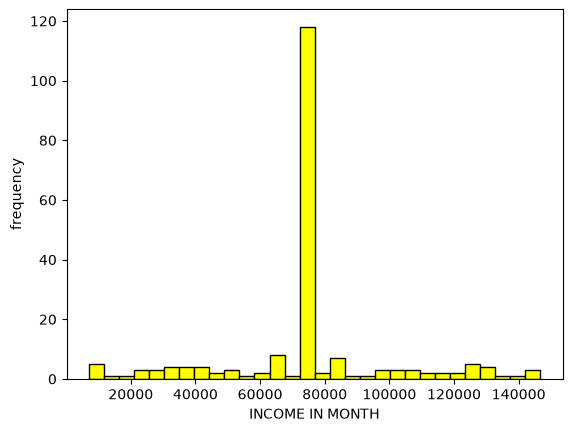

In [169]:
# HISTOGRAM FOR MONTHLY INCOME
plt.hist(df_clean['monthly_income_nrs'], bins=30, color='yellow',edgecolor='black')
plt.xlabel('INCOME IN MONTH')
plt.ylabel('frequency')

# 27. Summary Dashboard and Statistical Report

The final section brings together several important findings from the exploratory analysis into a single report.

The report includes:

- Total number of respondents
- Average monthly income
- Average household size
- Average land ownership
- Average annual remittance
- Most common occupation
- Most common education level
- Electricity access percentage
- Internet access percentage

The dashboard also combines multiple visualizations to provide a compact overview of demographic, socioeconomic, land-ownership, remittance, and digital-access patterns in the dataset.

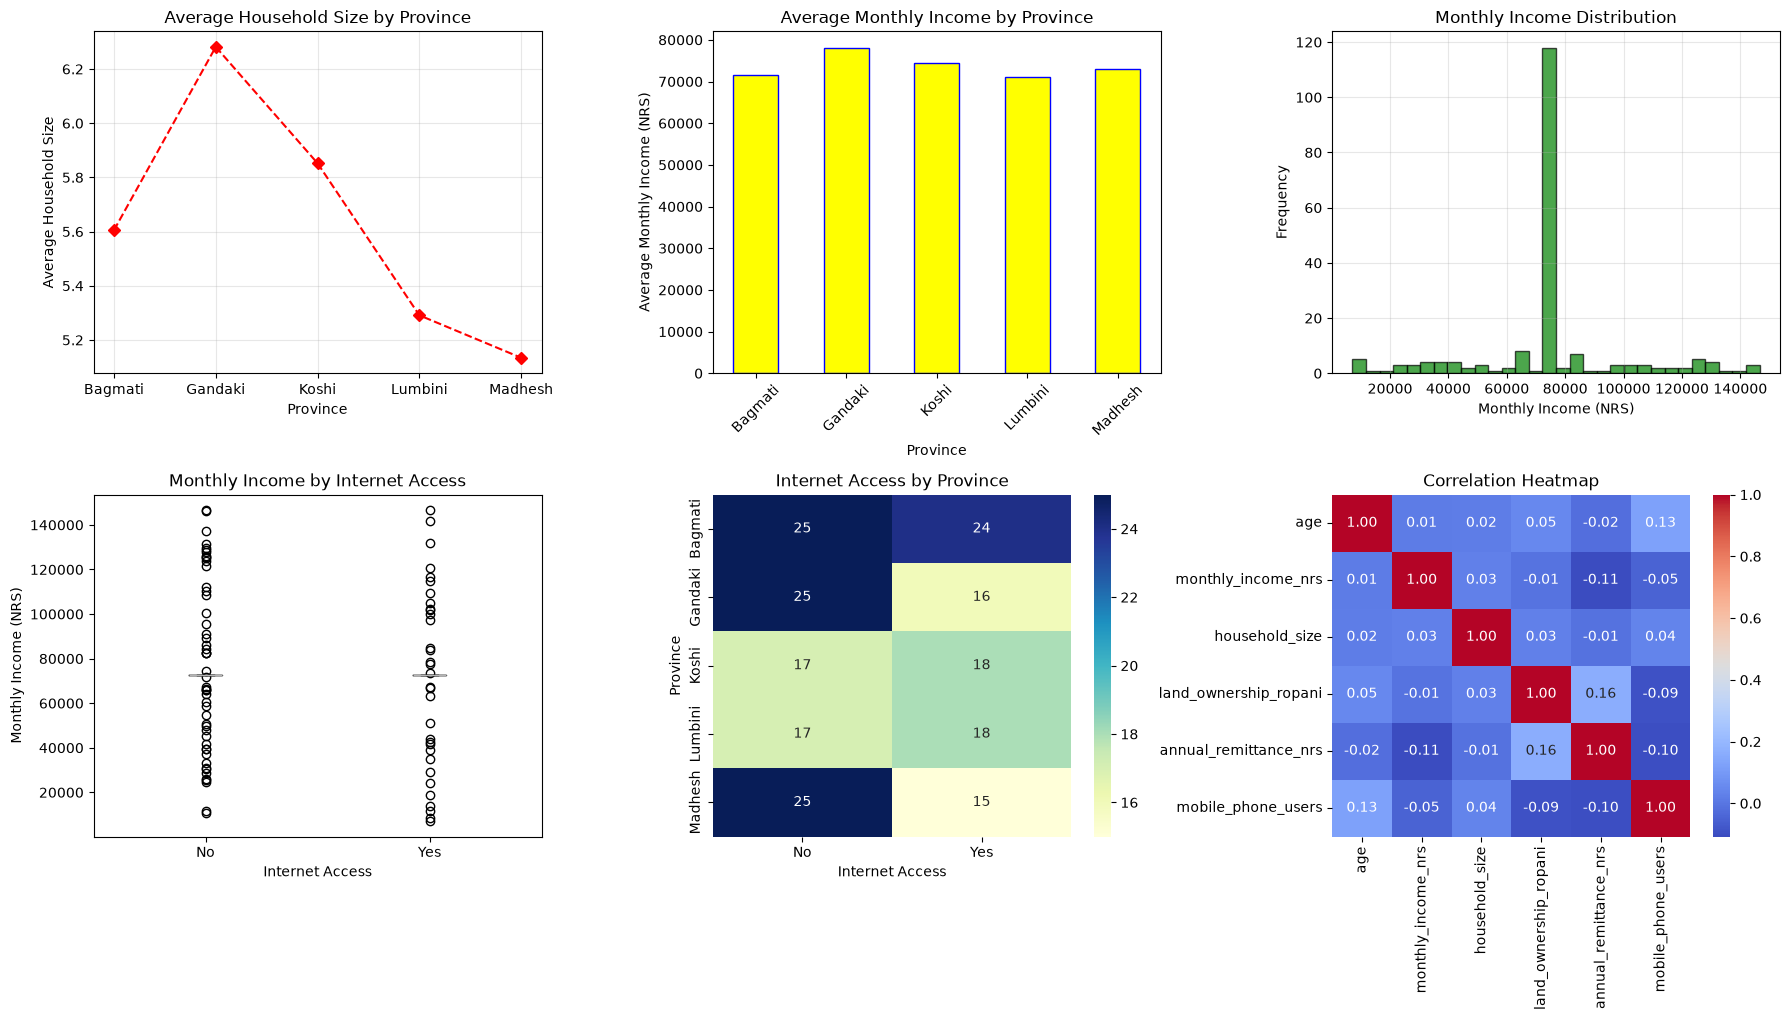

          HOUSEHOLD & SOCIOECONOMIC ANALYSIS REPORT
REPORT SCOPE:       200 Respondents Analyzed
AVERAGE INCOME:     NRs. 73,582.50 per month
AVERAGE HOUSEHOLD:  5.64 members
AVERAGE LAND:       9.41 Ropani
------------------------------------------------------------
1. TOP OCCUPATION:  'Daily Wage' is the most common occupation.
2. EDUCATION:       'SLC' is the most common education level.
3. LAND OWNERSHIP:  Average land ownership is 9.41 Ropani.
4. REMITTANCE:      Average annual remittance is NRs. 255,100.28.
------------------------------------------------------------
CRITICAL INSIGHTS:
- The dataset contains 200 respondents covering
  demographic and socioeconomic characteristics.
- Respondents have an average monthly income of NRs. 73,582.50, providing an overview of household income.
- The average household size is 5.64 members,
  indicating the typical household structure in the dataset.
- 'Daily Wage' is the most common occupation, while
  'SLC' is the most common education l

In [170]:
# CALCULATE REPORT VALUES

total_records = len(df_clean)
avg_income = df_clean['monthly_income_nrs'].mean()
avg_household_size = df_clean['household_size'].mean()
avg_land = df_clean['land_ownership_ropani'].mean()
avg_remittance = df_clean['annual_remittance_nrs'].mean()
top_occupation = df_clean['occupation'].value_counts().idxmax()
top_education = df_clean['education_level'].value_counts().idxmax()

electricity_percentage = (
    df_clean['electricity_access'].value_counts(normalize=True)['Yes'] * 100
)

internet_percentage = (
    df_clean['internet_access'].value_counts(normalize=True)['Yes'] * 100
)


# ============================================================
# MAIN 2 × 3 DASHBOARD GRID
# ============================================================

fig, axs = plt.subplots(2, 3, figsize=(18, 11))

fig.suptitle(
    'NEPAL HOUSEHOLD & SOCIOECONOMIC ANALYSIS REPORT',
    fontsize=16,
    fontweight='bold'
)


# ============================================================
# CHART 1 - LINE PLOT
# AVERAGE HOUSEHOLD SIZE BY PROVINCE
# ============================================================

avg_size = df_clean.groupby('province')['household_size'].mean()

axs[0, 0].plot(
    avg_size.index,
    avg_size.values,
    color='red',
    marker='D',
    linestyle='--'
)

axs[0, 0].set_title(
    'Average Household Size by Province',
    fontsize=12
)

axs[0, 0].set_xlabel('Province')
axs[0, 0].set_ylabel('Average Household Size')
axs[0, 0].grid(True, alpha=0.3)


# ============================================================
# CHART 2 - BAR PLOT
# AVERAGE MONTHLY INCOME BY PROVINCE
# ============================================================

avg_income_monthly = (
    df_clean.groupby('province')['monthly_income_nrs'].mean()
)

axs[0, 1].bar(
    avg_income_monthly.index,
    avg_income_monthly.values,
    color='yellow',
    width=0.5,
    edgecolor='blue'
)

axs[0, 1].set_title(
    'Average Monthly Income by Province',
    fontsize=12
)

axs[0, 1].set_xlabel('Province')
axs[0, 1].set_ylabel('Average Monthly Income (NRS)')

axs[0, 1].tick_params(axis='x', rotation=45)


# ============================================================
# CHART 3 - HISTOGRAM
# MONTHLY INCOME DISTRIBUTION
# ============================================================

axs[0, 2].hist(
    df_clean['monthly_income_nrs'],
    bins=30,
    color='green',
    alpha=0.7,
    edgecolor='black'
)

axs[0, 2].set_title(
    'Monthly Income Distribution',
    fontsize=12
)

axs[0, 2].set_xlabel('Monthly Income (NRS)')
axs[0, 2].set_ylabel('Frequency')
axs[0, 2].grid(True, alpha=0.3)


# ============================================================
# CHART 4 - BOX PLOT
# MONTHLY INCOME BY INTERNET ACCESS
# ============================================================

df_clean.boxplot(
    column='monthly_income_nrs',
    by='internet_access',
    grid=False,
    ax=axs[1, 0]
)

axs[1, 0].set_title(
    'Monthly Income by Internet Access',
    fontsize=12
)

axs[1, 0].set_xlabel('Internet Access')
axs[1, 0].set_ylabel('Monthly Income (NRS)')

# Remove pandas' automatic extra title
plt.suptitle('')


# ============================================================
# CHART 5 - HEATMAP
# PROVINCE VS INTERNET ACCESS
# ============================================================

heatmap_data = pd.crosstab(
    df_clean['province'],
    df_clean['internet_access']
)

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='d',
    cmap='YlGnBu',
    ax=axs[1, 1]
)

axs[1, 1].set_title(
    'Internet Access by Province',
    fontsize=12
)

axs[1, 1].set_xlabel('Internet Access')
axs[1, 1].set_ylabel('Province')


# ============================================================
# CHART 6 - CORRELATION HEATMAP
# ============================================================

correlation_data = df_clean[
    [
        'age',
        'monthly_income_nrs',
        'household_size',
        'land_ownership_ropani',
        'annual_remittance_nrs',
        'mobile_phone_users'
    ]
].corr()

sns.heatmap(
    correlation_data,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    ax=axs[1, 2]
)

axs[1, 2].set_title(
    'Correlation Heatmap',
    fontsize=12
)
plt.savefig(r"C:\Users\Dell\OneDrive\Desktop\ALL PROJECTS\DATA-SCIENCE-PROJECTS\PROJECT-3\Dashboard\nepal_household_dashboard.png", dpi=300, bbox_inches='tight')


# ============================================================
# ADJUST DASHBOARD LAYOUT
# ============================================================

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.show()


# ============================================================
# TEXT-BASED SUMMARY REPORT
# ============================================================

print("=" * 60)
print("          HOUSEHOLD & SOCIOECONOMIC ANALYSIS REPORT")
print("=" * 60)

print(f"REPORT SCOPE:       {total_records:,} Respondents Analyzed")
print(f"AVERAGE INCOME:     NRs. {avg_income:,.2f} per month")
print(f"AVERAGE HOUSEHOLD:  {avg_household_size:.2f} members")
print(f"AVERAGE LAND:       {avg_land:.2f} Ropani")

print("-" * 60)

print(
    f"1. TOP OCCUPATION:  '{top_occupation}' is the most common occupation."
)

print(
    f"2. EDUCATION:       '{top_education}' is the most common education level."
)

print(
    f"3. LAND OWNERSHIP:  Average land ownership is {avg_land:.2f} Ropani."
)

print(
    f"4. REMITTANCE:      Average annual remittance is "
    f"NRs. {avg_remittance:,.2f}."
)

print("-" * 60)

print("CRITICAL INSIGHTS:")

print(
    f"- The dataset contains {total_records:,} respondents covering"
)
print(
    "  demographic and socioeconomic characteristics."
)

print(
    f"- Respondents have an average monthly income of "
    f"NRs. {avg_income:,.2f}, providing an overview of household income."
)

print(
    f"- The average household size is {avg_household_size:.2f} members,"
)
print(
    "  indicating the typical household structure in the dataset."
)

print(
    f"- '{top_occupation}' is the most common occupation, while"
)
print(
    f"  '{top_education}' is the most common education level."
)

print(
    f"- Average land ownership is {avg_land:.2f} Ropani,"
)
print(
    "  providing an indication of household land access."
)

print(
    f"- Average annual remittance is NRs. {avg_remittance:,.2f},"
)
print(
    "  highlighting the contribution of remittance income."
)

print(
    f"- Electricity access is available to "
    f"{electricity_percentage:.1f}% of respondents."
)

print(
    f"- Internet access is available to "
    f"{internet_percentage:.1f}% of respondents, "
    "showing the level of digital connectivity."
)

print("=" * 60)